# Schachner Model

Michael Schachner reviews wines from many countries, which makes these reviews a natural test of the taster-vs-origin confound: the **taster stays fixed**, so any differences between countries are closer to real origin signal.

Only the **training split** is used here, so validation and test stay untouched.

In [1]:
import re

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
DATA = "data_clean/splits/train.parquet"
TASTER = "Michael Schachner"

# Fixed colors so each country looks the same in every plot
COLORS = {"Spain": "#c0392b", "Chile": "#2471a3", "Argentina": "#5dade2", "Other": "#95a5a6"}
MAIN = ["Spain", "Chile", "Argentina"]
TOKEN = r"(?u)\b[^\W\d_]{3,}\b"   # words of 3+ letters, no numbers

## 1. Split out Schachner's reviews

In [3]:
train = pd.read_parquet(DATA)
sch = train[train["taster_name"] == TASTER].copy()
sch["n_words"] = sch["description"].str.split().str.len()
sch["country_main"] = sch["country"].where(sch["country"].isin(MAIN), "Other")

sch.to_parquet("data_clean/schachner_train.parquet")
print(f"{len(sch):,} Schachner reviews out of {len(train):,} training reviews "
      f"({len(sch) / len(train):.1%})")
sch.head()

9,838 Schachner reviews out of 83,945 training reviews (11.7%)


,country,description,designation,points,price,province,region_1,region_2,taster_name,title,variety,winery,vintage,log_price,price_missing,country_group,n_words,country_main
34,Spain,Focused crisp aromas of white fruits reflect a...,Brut Natural Reserva,90,25.0,Catalonia,Penedès,NaN,Michael Schachner,Albet I Noya 2013 Brut Natural Reserva Sparkli...,Sparkling Blend,Albet I Noya,2013,3.218876,False,Spain,42,Spain
47,Chile,"Opens with roasted, herbal aromas that suggest...",1865 Limited Edition,89,25.0,Cachapoal Valley,NaN,NaN,Michael Schachner,San Pedro 2008 1865 Limited Edition Cabernet S...,Cabernet Sauvignon-Syrah,San Pedro,2008,3.218876,False,Chile,39,Chile
77,Chile,"Surprise! This is a legitimate, true to the va...",Reserve,87,11.0,Bío Bío Valley,NaN,NaN,Michael Schachner,Gracia de Chile 2006 Reserve Pinot Noir (Bío B...,Pinot Noir,Gracia de Chile,2006,2.397895,False,Chile,61,Chile
110,Chile,Although this Cab is scratchy on the nose and ...,Urban,85,13.0,Maule Valley,NaN,NaN,Michael Schachner,O. Fournier 2011 Urban Cabernet Sauvignon (Mau...,Cabernet Sauvignon,O. Fournier,2011,2.564949,False,Chile,41,Chile
120,Spain,"Falls into the dark and roasted category, with...",Crianza,88,19.0,Northern Spain,Rioja,NaN,Michael Schachner,Marques de Tomares 2006 Crianza (Rioja),Tempranillo Blend,Marques de Tomares,2006,2.944439,False,Spain,49,Spain


## 2. Which countries does Schachner review?

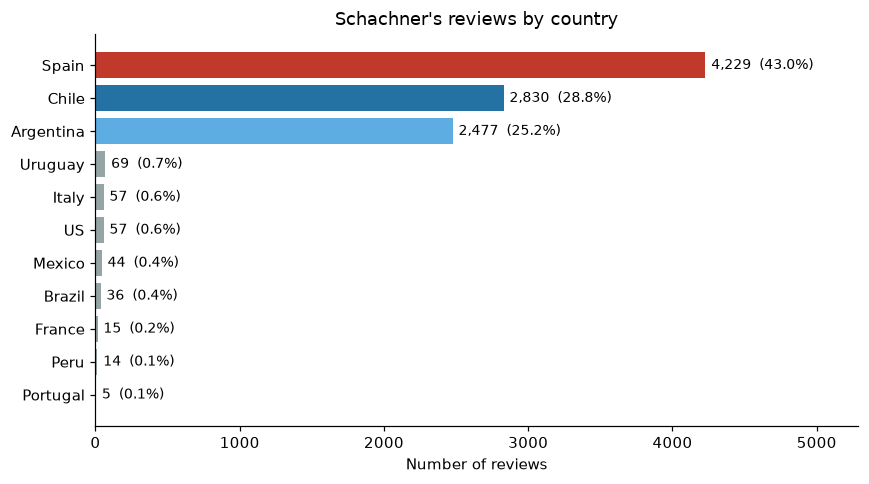

Spain + Chile + Argentina = 97.0% of Schachner's reviews


In [4]:
counts = sch["country"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
bar_colors = [COLORS.get(c, COLORS["Other"]) for c in counts.index]
ax.barh(counts.index[::-1], counts.values[::-1], color=bar_colors[::-1])
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 40, i, f"{v:,}  ({v / counts.sum():.1%})", va="center", fontsize=9)
ax.set_xlabel("Number of reviews")
ax.set_title("Schachner's reviews by country")
ax.set_xlim(0, counts.max() * 1.25)
plt.tight_layout()
plt.show()

print(f"Spain + Chile + Argentina = {counts[MAIN].sum() / counts.sum():.1%} of Schachner's reviews")

### How much of each country's coverage is Schachner?
If one taster writes most reviews for a country, a country classifier can just learn that taster's style. This is the confound in one picture.

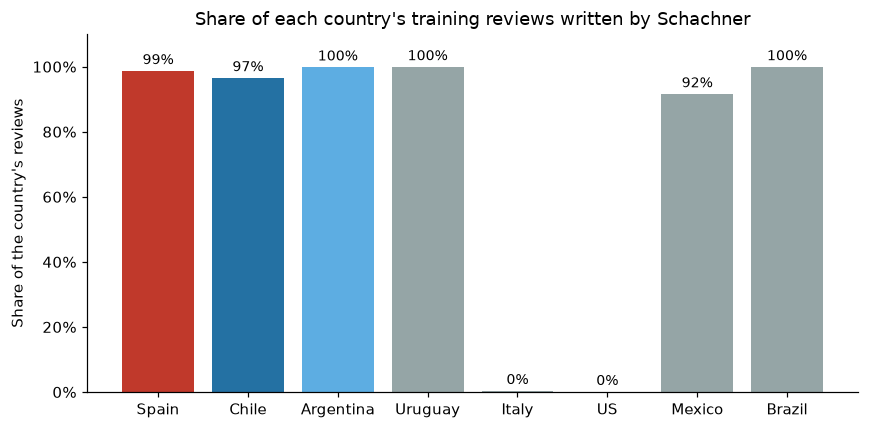

In [5]:
top_countries = counts.index[:8]
share = (train[train["country"].isin(top_countries)]
         .assign(is_sch=lambda d: d["taster_name"] == TASTER)
         .groupby("country")["is_sch"].mean()
         .reindex(top_countries))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(share.index, share.values, color=[COLORS.get(c, COLORS["Other"]) for c in share.index])
for i, v in enumerate(share.values):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.1)
ax.set_ylabel("Share of the country's reviews")
ax.set_title("Share of each country's training reviews written by Schachner")
plt.tight_layout()
plt.show()

## 3. Scores, prices and review length by country

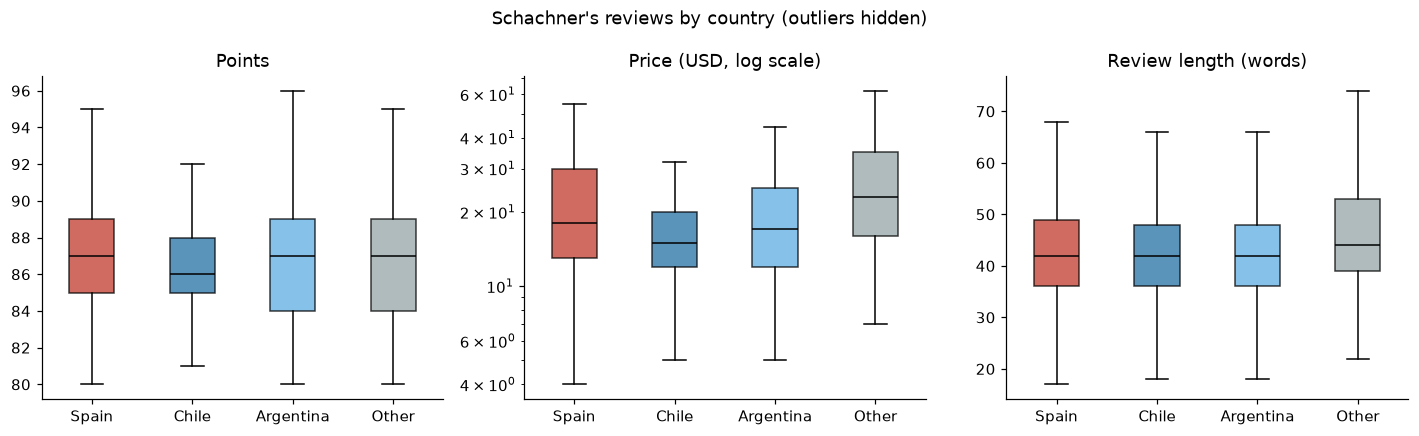

points        price        n_words       
               mean median  mean median    mean median
country_main                                          
Spain          87.3   87.0  28.4   18.0    42.9   42.0
Chile          86.5   86.0  20.7   15.0    42.7   42.0
Argentina      86.7   87.0  24.5   17.0    42.3   42.0
Other          86.4   87.0  29.0   23.0    45.6   44.0

In [6]:
groups = MAIN + ["Other"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, title in [
    (axes[0], "points", "Points"),
    (axes[1], "price", "Price (USD, log scale)"),
    (axes[2], "n_words", "Review length (words)"),
]:
    data = [sch.loc[sch["country_main"] == g, col].dropna() for g in groups]
    bp = ax.boxplot(data, tick_labels=groups, patch_artist=True, showfliers=False)
    for patch, g in zip(bp["boxes"], groups):
        patch.set_facecolor(COLORS[g])
        patch.set_alpha(0.75)
    for med in bp["medians"]:
        med.set_color("black")
    ax.set_title(title)

axes[1].set_yscale("log")
fig.suptitle("Schachner's reviews by country (outliers hidden)")
plt.tight_layout()
plt.show()

sch.groupby("country_main")[["points", "price", "n_words"]].agg(["mean", "median"]).round(1).reindex(groups)

### Points vs. price
Does Schachner reward price the same way in each country?

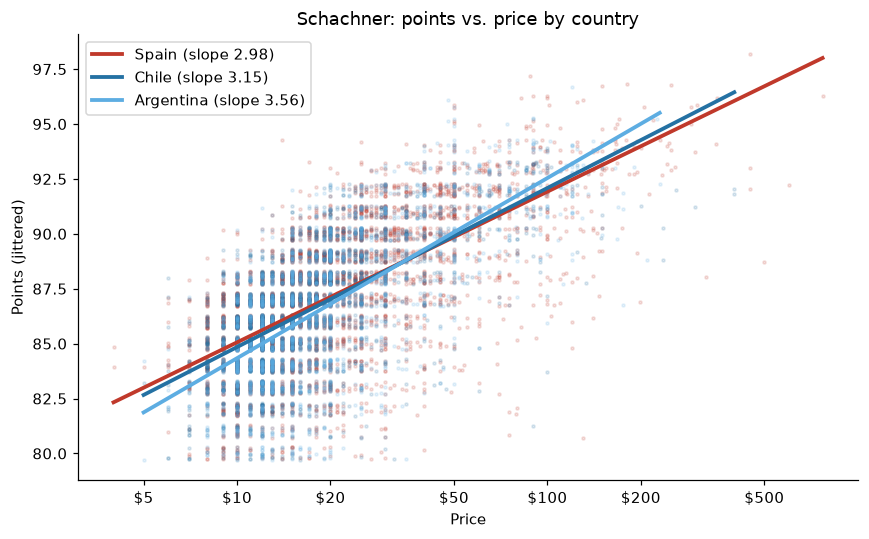

In [7]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 5))
for c in MAIN:
    d = sch[(sch["country"] == c) & sch["price"].notna()]
    ax.scatter(d["log_price"], d["points"] + rng.uniform(-0.3, 0.3, len(d)),
               s=4, alpha=0.15, color=COLORS[c])
    slope, intercept = np.polyfit(d["log_price"], d["points"], 1)
    xs = np.linspace(d["log_price"].min(), d["log_price"].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=COLORS[c], lw=2.5,
            label=f"{c} (slope {slope:.2f})")

ticks = [5, 10, 20, 50, 100, 200, 500]
ax.set_xticks(np.log(ticks), [f"${t}" for t in ticks])
ax.set_xlabel("Price")
ax.set_ylabel("Points (jittered)")
ax.set_title("Schachner: points vs. price by country")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Grape varieties by country
Variety is the main thing mixed up with origin: Malbec says Argentina, Tempranillo says Spain, Carmenère says Chile. The heatmap shows what share of each country's reviews each variety makes up.

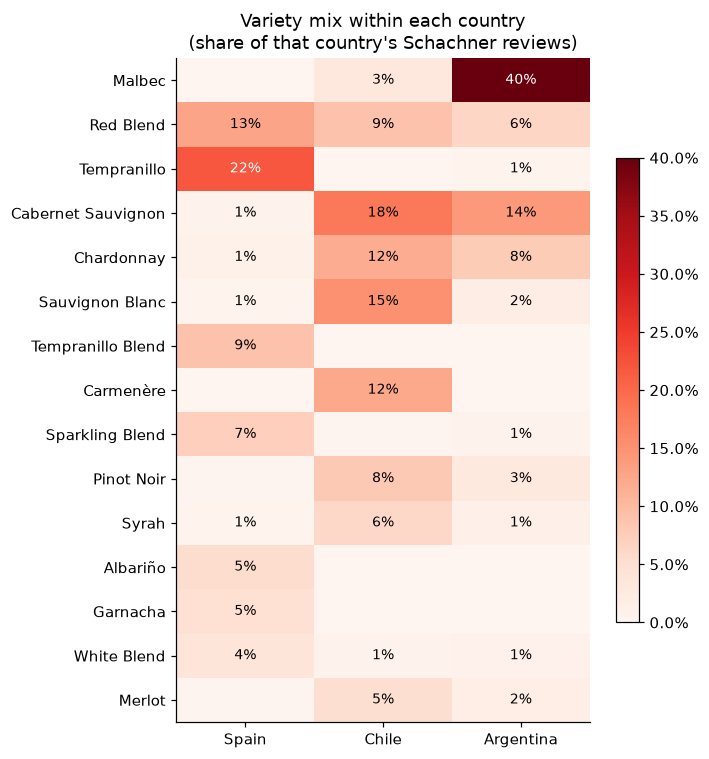

Varieties with >2% share in at least two countries: ['Malbec', 'Red Blend', 'Cabernet Sauvignon', 'Chardonnay', 'Pinot Noir']


In [8]:
main = sch[sch["country"].isin(MAIN)].reset_index(drop=True)
top_var = main["variety"].value_counts().index[:15]
var_mix = pd.crosstab(main["variety"], main["country"], normalize="columns").reindex(top_var)[MAIN]

fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(var_mix.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(MAIN)), MAIN)
ax.set_yticks(range(len(top_var)), top_var)
for i in range(var_mix.shape[0]):
    for j in range(var_mix.shape[1]):
        v = var_mix.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center",
                    color="white" if v > 0.2 else "black", fontsize=9)
ax.set_title("Variety mix within each country\n(share of that country's Schachner reviews)")
plt.colorbar(im, ax=ax, format=PercentFormatter(1), shrink=0.7)
plt.tight_layout()
plt.show()

shared = var_mix[(var_mix > 0.02).sum(axis=1) >= 2].index.tolist()
print("Varieties with >2% share in at least two countries:", shared)

## 5. Words that set each country apart
Log-odds ratio with an informative prior (Monroe et al., 2008): how much more often Schachner uses a word for one country than for the other two. Positive means the word leans toward that country.

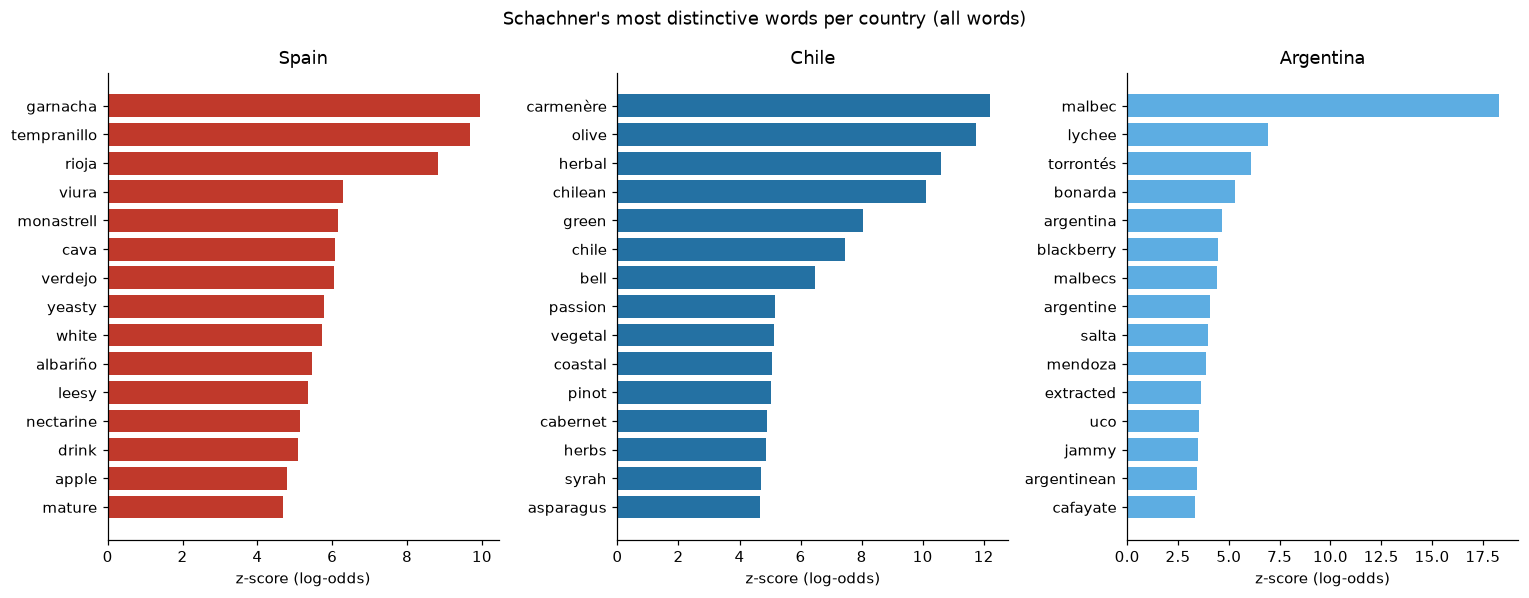

In [9]:
def log_odds_z(texts, mask, min_df=10):
    """z-scored log-odds of each word: reviews where mask is True vs. the rest."""
    cv = CountVectorizer(min_df=min_df, token_pattern=TOKEN)
    X = cv.fit_transform(texts.str.lower())
    prior = np.asarray(X.sum(axis=0)).ravel() + 0.01
    a0 = prior.sum()
    y_i = np.asarray(X[mask].sum(axis=0)).ravel()
    y_j = np.asarray(X[~mask].sum(axis=0)).ravel()
    d = (np.log((y_i + prior) / (y_i.sum() + a0 - y_i - prior))
         - np.log((y_j + prior) / (y_j.sum() + a0 - y_j - prior)))
    return pd.Series(d / np.sqrt(1 / (y_i + prior) + 1 / (y_j + prior)), index=cv.get_feature_names_out())


z = {c: log_odds_z(main["description"], (main["country"] == c).values) for c in MAIN}


def plot_top_words(zdict, title, n=15):
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
    for ax, c in zip(axes, MAIN):
        top = zdict[c].nlargest(n)[::-1]
        ax.barh(top.index, top.values, color=COLORS[c])
        ax.set_title(c)
        ax.set_xlabel("z-score (log-odds)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_top_words(z, "Schachner's most distinctive words per country (all words)")

### Same thing, with place names and grape varieties removed
Words like *malbec* or *rioja* name the answer outright. Removing them shows whether Schachner describes the wines themselves differently by country.

In [10]:
# Words taken from the grape and place columns.
# (winery / designation are left out on purpose: they contain ordinary words like "oak" or "green".)
name_tokens = set()
for col in ["variety", "province", "region_1", "region_2", "country"]:
    for val in sch[col].dropna().unique():
        name_tokens.update(re.findall(r"[^\W\d_]{3,}", val.lower()))

# Ordinary words that happen to appear in those columns: keep them as descriptive words
name_tokens -= {"and", "other", "red", "white", "style", "sparkling", "blend", "northern"}

# Plurals, nicknames, nationality words and label terms that point straight at a country
name_tokens |= {"malbecs", "cab", "cabs", "carmenere", "carmenères", "torrontes", "tempranillos",
                "chardonnays", "spanish", "chilean", "argentine", "argentinean", "argentinian",
                "andes", "uco", "colchagua", "crianza", "reserva", "gran"}

print(sorted(name_tokens & set(z[MAIN[0]].index)))

['albariño', 'alta', 'argentina', 'argentine', 'argentinean', 'blanc', 'blanca', 'blanco', 'bobal', 'bonarda', 'bordeaux', 'cab', 'cabernet', 'cafayate', 'carignan', 'carmenère', 'casablanca', 'cava', 'central', 'chardonnay', 'chile', 'chilean', 'crianza', 'del', 'duero', 'elqui', 'fino', 'franc', 'garnacha', 'godello', 'graciano', 'gran', 'grenache', 'leyda', 'macabeo', 'maipo', 'malbec', 'malbecs', 'malvasia', 'maule', 'mencía', 'mendoza', 'merlot', 'monastrell', 'moscatel', 'mourvèdre', 'navarra', 'noir', 'pedro', 'petit', 'picudo', 'pinot', 'prieto', 'priorat', 'reserva', 'ribera', 'riesling', 'rioja', 'rosado', 'rosé', 'rueda', 'salta', 'san', 'santa', 'sauvignon', 'sherry', 'shiraz', 'spain', 'spanish', 'syrah', 'tannat', 'tempranillo', 'tinto', 'toro', 'torrontés', 'treixadura', 'trepat', 'uco', 'valencia', 'valley', 'verdejo', 'verdot', 'viognier', 'viura']


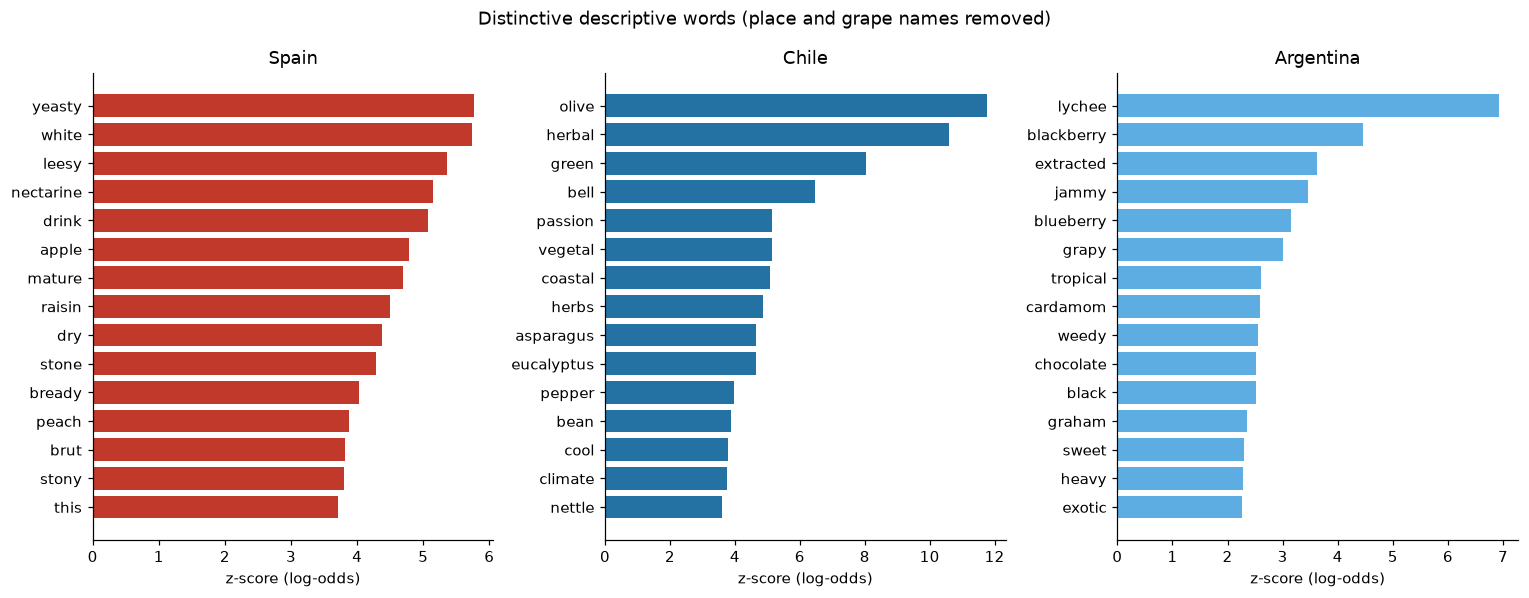

Removed 84 of 2,049 vocabulary words as names


In [11]:


z_clean = {c: s[~s.index.isin(name_tokens)] for c, s in z.items()}
plot_top_words(z_clean, "Distinctive descriptive words (place and grape names removed)")

vocab = z[MAIN[0]].index
print(f"Removed {vocab.isin(list(name_tokens)).sum():,} of {len(vocab):,} vocabulary words as names")

## 6. Same grape, different country
Holding **both** the taster and the grape fixed is the cleanest look at origin. If Schachner still writes differently about Chilean and Argentine Cabernet, that's origin signal.

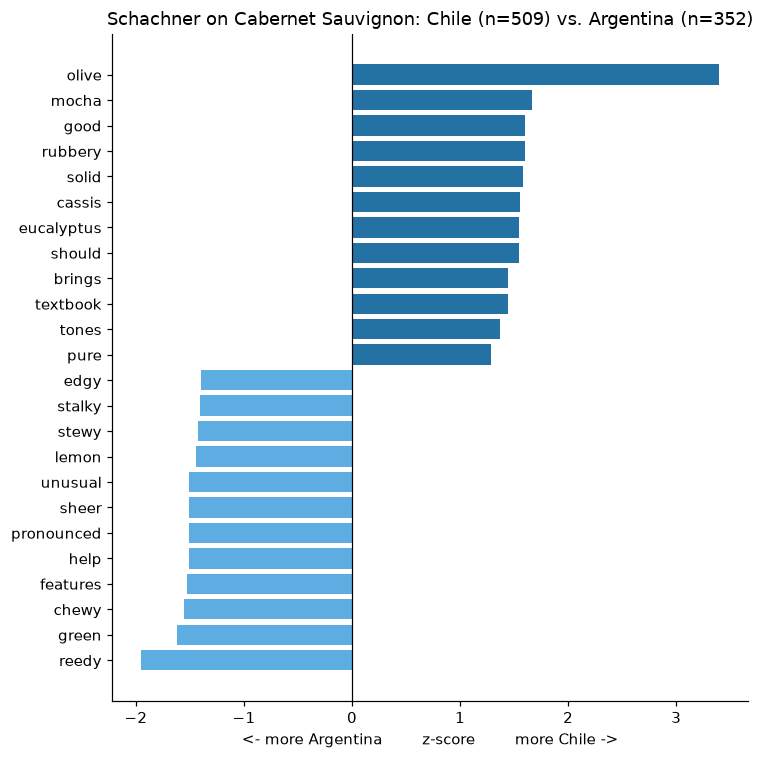

In [12]:
def compare_variety(variety, c1, c2, n=12):
    d = main[(main["variety"] == variety) & main["country"].isin([c1, c2])].reset_index(drop=True)
    m = (d["country"] == c1).values
    zz = log_odds_z(d["description"], m, min_df=5)
    zz = zz[~zz.index.isin(name_tokens)]
    sel = pd.concat([zz.nsmallest(n), zz.nlargest(n)[::-1]])

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.barh(sel.index, sel.values, color=[COLORS[c1] if v > 0 else COLORS[c2] for v in sel.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(f"<- more {c2}        z-score        more {c1} ->")
    ax.set_title(f"Schachner on {variety}: {c1} (n={m.sum()}) vs. {c2} (n={(~m).sum()})")
    plt.tight_layout()
    plt.show()


compare_variety("Cabernet Sauvignon", "Chile", "Argentina")

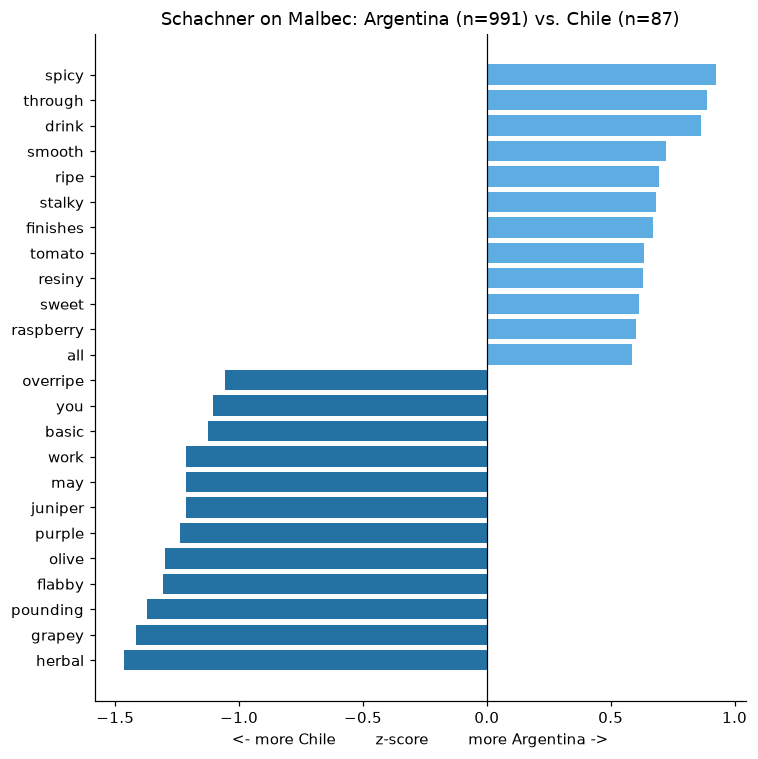

In [13]:
compare_variety("Malbec", "Argentina", "Chile")

## 7. Can a model tell the countries apart within Schachner's reviews?
A quick check using an 80/20 split *inside* Schachner's training reviews, with the same setup as the bias-variance model (logistic regression, TF-IDF, C=10, balanced classes). Run once with all words and once with place and grape names removed.

In [14]:
tr, te = train_test_split(main, test_size=0.2, stratify=main["country"], random_state=42)


def fit_eval(drop_words=None):
    vec = TfidfVectorizer(max_features=10_000, sublinear_tf=True, stop_words=drop_words,
                          token_pattern=TOKEN)
    Xtr = vec.fit_transform(tr["description"].str.lower())
    Xte = vec.transform(te["description"].str.lower())
    clf = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
    clf.fit(Xtr, tr["country"])
    pred = clf.predict(Xte)
    return pred, accuracy_score(te["country"], pred), f1_score(te["country"], pred, average="macro")


pred_all, acc_all, f1_all = fit_eval()
pred_clean, acc_clean, f1_clean = fit_eval(drop_words=sorted(name_tokens))
majority = te["country"].value_counts(normalize=True).iloc[0]

results = pd.DataFrame({
    "accuracy": [majority, acc_all, acc_clean],
    "macro F1": [np.nan, f1_all, f1_clean],
}, index=["Always guess Spain", "All words", "Names removed"]).round(3)
results

,accuracy,macro F1
Always guess Spain,0.443,NaN
All words,0.649,0.633
Names removed,0.534,0.521


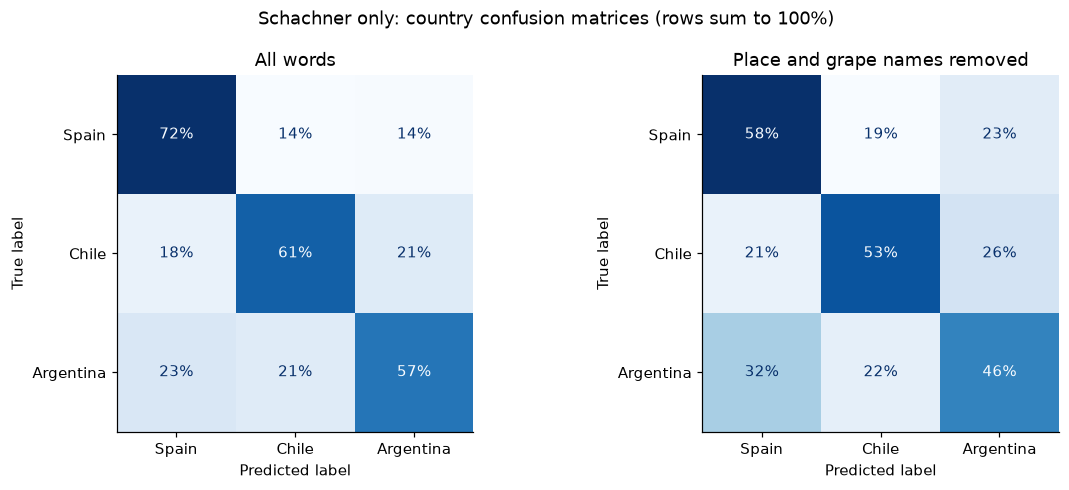

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in [(axes[0], pred_all, "All words"),
                        (axes[1], pred_clean, "Place and grape names removed")]:
    ConfusionMatrixDisplay.from_predictions(te["country"], pred, labels=MAIN, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
fig.suptitle("Schachner only: country confusion matrices (rows sum to 100%)")
plt.tight_layout()
plt.show()

## Takeaways

**1. Schachner and the country are nearly the same thing in this data.**
Schachner wrote 99% of Spain's, 97% of Chile's and 100% of Argentina's training reviews. Those three countries make up 97% of Schachner's 9,838 reviews. On the full dataset, a model separating these countries can't be distinguished from a model that recognizes Schachner's writing, so a within-taster comparison is the only way to separate the two.

**2. Scores, prices and review length barely change by country.**
- Median points are 87 for Spain, 86 for Chile and 87 for Argentina.
- The median review is 42 words in all three.
- Price predicts points about equally in each country: the slopes are 3.0 (Spain), 3.2 (Chile) and 3.6 (Argentina) points per log-dollar.
- Schachner doesn't score one country more harshly. The differences are in *what* gets said, not how much or how generously.

**3. Grape variety carries much of the country signal.**
Malbec is 40% of Argentina's reviews, Tempranillo 22% of Spain's and Carmenère 12% of Chile's. Only five varieties appear above 2% in more than one country: Malbec, Red Blend, Cabernet Sauvignon, Chardonnay and Pinot Noir. Without a careful setup, "predict the country" is largely "predict the grape".

**4. With place and grape names removed, each country still has its own vocabulary:**
- **Chile:** green and herbal (*olive, herbal, green, bell pepper, vegetal, asparagus, eucalyptus, nettle*) plus climate words (*coastal, cool, climate*). This fits Chile's cooler, coastal-influenced growing areas.
- **Argentina:** riper and heavier (*blackberry, blueberry, jammy, extracted, sweet, heavy, chocolate*). *Lychee* and *exotic* come from Torrontés white wines.
- **Spain:** sparkling-wine and older-wine words (*yeasty, leesy, bready, brut* from Cava; *mature, raisin, dusty*) and white stone fruit (*nectarine, peach, apple, stony*).

**5. With both taster and grape held fixed, most of the difference disappears.**
- **Cabernet Sauvignon, Chile (509 reviews) vs. Argentina (352):** only *olive* clearly leans Chilean (z ≈ 3.4). Every other word has |z| < 2, which is within noise.
- **Malbec, Argentina (991) vs. Chile (87):** no word reaches |z| > 1.5, though the Chilean sample is small.

So the country vocabulary in point 4 mostly reflects *which grapes* each country makes, not how Schachner describes the same grape from different places.

**6. A model can only partly recover country from Schachner's text.**

| Model (80/20 split inside Schachner's reviews) | Accuracy | Macro F1 |
|---|---|---|
| Always guess Spain | 44.3% | — |
| All words | 64.9% | 0.633 |
| Place and grape names removed | 53.4% | 0.521 |

- Even with grape names allowed, the model reaches only about 65%. Only 24% of Argentine reviews actually say "malbec", so the giveaway words are often missing.
- Removing names takes away about 11 points. Roughly **9 points above guessing** is the origin signal left once both taster and names are removed.
- Argentina is the hardest country: after removal, 32% of Argentine reviews are predicted as Spain.
- Changing the regularization strength (C from 0.3 to 10) moves accuracy by only about 2 points, so the ceiling comes from the data, not the model settings.

**What this means for the project:** the 85.8% country accuracy on the full data overstates the real origin signal. With the taster held fixed, country is only modestly predictable from the text. The remaining signal comes mainly from grape mix, plus a smaller real stylistic difference (Chile's "green" profile is the clearest). To confirm the pattern, repeat this analysis for another multi-country taster, such as Czerwinski or Voss.
